# Day 2 - Retrieval Pipeline
## Trustworthy Evidence-Grounded Framework - FEVEROUS Validation

**Objectives:**
1. Load frozen `claims.json` and `evidence_corpus.json` from Day 1
2. Embed the entire evidence corpus with `all-MiniLM-L6-v2`
3. Build a FAISS index for fast approximate nearest-neighbour retrieval
4. For each claim, retrieve top-K evidence items
5. Compute Retrieval Precision@K and Recall@K against gold evidence IDs
6. Save `retrieval_results.csv` (first real metric!)

---
**Expected runtime:** ~20 min (embedding ~4,571 items + 450 queries on T4)

> **Package versions are pinned to match the working Day 1 environment.**

In [5]:
# Cell 1: Install — versions pinned to match Day 1 working environment
# datasets==2.15.0 / huggingface_hub==0.19.4 / fsspec==2023.10.0 are required
# because newer datasets versions drop support for the FEVEROUS dataset script.
!pip install -q \
    "datasets==2.15.0" \
    "huggingface_hub==0.19.4" \
    "fsspec==2023.10.0" \
    sentence-transformers \
    faiss-cpu \
    transformers \
    accelerate \
    bitsandbytes
print('Packages ready')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.26.0+cu128 requires torch==2.11.0, but you have torch 2.13.0 which is incompatible.
pyiceberg 0.11.1 requires rich<15.0.0,>=10.11.0, but you have rich 15.0.0 which is incompatible.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.19.4 which is incompatible.
peft 0.19.1 requires huggingface_hub>=0.25.0, but you have huggingface-hub 0.19.4 which is incompatible.
cudf-cu12 26.2.1 requires cuda-toolkit[nvcc,nvrtc]==12.*, but you have cuda-toolkit 13.0.3.0 which is incompatible.
bigframes 2.42.0 requires rich<14,>=12.4.4, but you have rich 15.0.0 which is incompatible.
cuml-cu12 26.2.0 requires cuda-toolkit[cublas,cufft,curand,cusolver,cusparse]==12.*, but you have cuda-toolkit 13.0.3.0 which is incompatible.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2

In [4]:
# Cell 2: Mount Drive and set paths
from google.colab import drive
drive.mount('/content/drive')

import os
BASE_DIR = '/content/drive/MyDrive/feverous-validation'
DATA_DIR = os.path.join(BASE_DIR, 'data')
OUT_DIR  = os.path.join(BASE_DIR, 'outputs')
os.makedirs(OUT_DIR, exist_ok=True)
print('Drive mounted, paths ready')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted, paths ready


In [4]:
!pip install -q --upgrade --force-reinstall "numpy==1.26.4" "scikit-learn" "scipy" "sentence-transformers"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 6.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 77.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.2/35.2 MB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 611.3/611.3 kB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 784.9/784.9 kB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 309.1/309.1 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 461.0/461.0 kB 43.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 526.6/526.6 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [7]:
!pip uninstall -y torch torchvision torchaudio sentence-transformers transformers
!pip install -q "torch==2.4.1" "torchvision==0.19.1" "torchaudio==2.4.1"
!pip install -q "sentence-transformers==3.2.1" "transformers==4.46.3"

Found existing installation: torch 2.13.0
Uninstalling torch-2.13.0:
  Successfully uninstalled torch-2.13.0
Found existing installation: torchvision 0.26.0+cu128
Uninstalling torchvision-0.26.0+cu128:
  Successfully uninstalled torchvision-0.26.0+cu128
Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128
Found existing installation: sentence-transformers 3.1.1
Uninstalling sentence-transformers-3.1.1:
  Successfully uninstalled sentence-transformers-3.1.1
Found existing installation: transformers 4.40.2
Uninstalling transformers-4.40.2:
  Successfully uninstalled transformers-4.40.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.0/797.0 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 129.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 118.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 4.1 MB/s eta 0:00:00
   ━

In [1]:
import numpy as np
print("NumPy:", np.__version__)

from sentence_transformers import SentenceTransformer
print("SentenceTransformers import OK")

NumPy: 1.26.4


/usr/local/lib/python3.12/dist-packages/sentence_transformers/cross_encoder/CrossEncoder.py:13: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm, trange


SentenceTransformers import OK


In [2]:
# Cell 3: Imports
import json
import csv
import time
import numpy as np
import faiss
from sentence_transformers import SentenceTransformer
from tqdm.notebook import tqdm

print('Imports ready')

Imports ready


In [5]:
# Cell 4: Load frozen dataset
with open(os.path.join(DATA_DIR, 'claims.json'), encoding='utf-8') as f:
    claims = json.load(f)

with open(os.path.join(DATA_DIR, 'evidence_corpus.json'), encoding='utf-8') as f:
    evidence_corpus = json.load(f)

print(f'Claims loaded:   {len(claims)}')
print(f'Evidence corpus: {len(evidence_corpus)}')

# Sanity check — verify expected fields are present
assert 'claim' in claims[0] and 'gold_evidence' in claims[0], 'Unexpected claims.json structure'
assert 'ev_id' in evidence_corpus[0] and 'corpus_idx' in evidence_corpus[0], 'Unexpected evidence_corpus.json structure'

# Report evidence type breakdown for reference
from collections import Counter
type_counts = Counter(ev['type'] for ev in evidence_corpus)
print(f'Evidence type breakdown: {dict(type_counts)}')

print('\nSample claim:', claims[0]['claim'])
print('Sample corpus item:', evidence_corpus[0]['text'][:100])

Claims loaded:   450
Evidence corpus: 4571
Evidence type breakdown: {'cell': 1380, 'sentence': 2524, 'table_row': 667}

Sample claim: William Dering is first recorded as a dancing master in Philadelphia, he is said to have been respected as well for his talents on the French horn and in 1737 he moved to Gloucester County which was founded in 1651.
Sample corpus item: Funk Records: 1971


In [6]:
# Cell 5: Load MiniLM embedding model
print('Loading all-MiniLM-L6-v2 ...')
embedder = SentenceTransformer('all-MiniLM-L6-v2')
print('Model loaded. Embedding dimension:', embedder.get_sentence_embedding_dimension())

Loading all-MiniLM-L6-v2 ...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded. Embedding dimension: 384


In [7]:
# Cell 6: Embed evidence corpus
BATCH_SIZE = 256
corpus_texts = [ev['text'] for ev in evidence_corpus]

print(f'Embedding {len(corpus_texts)} evidence items (batch size {BATCH_SIZE}) ...')
t0 = time.time()

corpus_embeddings = embedder.encode(
    corpus_texts,
    batch_size=BATCH_SIZE,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True   # L2-normalize for cosine similarity via inner product
)

print(f'Done in {time.time()-t0:.1f}s. Shape: {corpus_embeddings.shape}')

Embedding 4571 evidence items (batch size 256) ...


Batches:   0%|          | 0/18 [00:00<?, ?it/s]

Done in 4.0s. Shape: (4571, 384)


In [8]:
# Cell 7: Build FAISS index (flat inner product = cosine similarity on L2-normalized vecs)
dim = corpus_embeddings.shape[1]
index = faiss.IndexFlatIP(dim)
index.add(corpus_embeddings.astype(np.float32))
print(f'FAISS index built. Total vectors: {index.ntotal}')

FAISS index built. Total vectors: 4571


In [9]:
# Cell 8: Embed all claim queries
claim_texts = [c['claim'] for c in claims]
print(f'Embedding {len(claim_texts)} claims ...')
t0 = time.time()
claim_embeddings = embedder.encode(
    claim_texts,
    batch_size=128,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print(f'Done in {time.time()-t0:.1f}s. Shape: {claim_embeddings.shape}')

Embedding 450 claims ...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Done in 0.4s. Shape: (450, 384)


In [10]:
# Cell 9: Retrieval + Precision@K / Recall@K computation
K_VALUES = [5, 10, 20]
MAX_K = max(K_VALUES)

print(f'Running FAISS search (top-{MAX_K}) for {len(claims)} claims ...')
scores, indices = index.search(claim_embeddings.astype(np.float32), MAX_K)
print('Search complete.')

def precision_at_k(retrieved_idxs, gold_idxs, k):
    retrieved_k = set(retrieved_idxs[:k])
    gold_set = set(gold_idxs)
    if not retrieved_k:
        return 0.0
    return len(retrieved_k & gold_set) / k

def recall_at_k(retrieved_idxs, gold_idxs, k):
    retrieved_k = set(retrieved_idxs[:k])
    gold_set = set(gold_idxs)
    if not gold_set:
        # No gold evidence (NEI or claims with zero resolved evidence).
        # Recall is undefined; we exclude these from the mean in Cell 11.
        return None
    return len(retrieved_k & gold_set) / len(gold_set)

results = []
for i, claim in enumerate(claims):
    gold_corpus_idxs = [
        ev['corpus_idx']
        for ev in claim['gold_evidence']
        if ev.get('corpus_idx', -1) >= 0
    ]
    retrieved_idxs  = indices[i].tolist()
    retrieved_scores = scores[i].tolist()

    row = {
        'claim_id':         claim['claim_id'],
        'label':            claim['label'],
        'n_gold':           len(gold_corpus_idxs),
        'retrieved_idxs':   json.dumps(retrieved_idxs),
        'retrieved_scores': json.dumps([round(s, 5) for s in retrieved_scores]),
        'gold_corpus_idxs': json.dumps(gold_corpus_idxs)
    }
    for k in K_VALUES:
        row[f'P@{k}'] = round(precision_at_k(retrieved_idxs, gold_corpus_idxs, k), 4)
        r = recall_at_k(retrieved_idxs, gold_corpus_idxs, k)
        row[f'R@{k}'] = round(r, 4) if r is not None else None
    results.append(row)

print(f'Results computed for {len(results)} claims')

Running FAISS search (top-20) for 450 claims ...
Search complete.
Results computed for 450 claims


In [11]:
# Cell 10: Save retrieval_results.csv
out_path = os.path.join(OUT_DIR, 'retrieval_results.csv')
fieldnames = ['claim_id', 'label', 'n_gold', 'retrieved_idxs', 'retrieved_scores',
              'gold_corpus_idxs'] + [f'P@{k}' for k in K_VALUES] + [f'R@{k}' for k in K_VALUES]

with open(out_path, 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(results)

print(f'Saved: {out_path}')

Saved: /content/drive/MyDrive/feverous-validation/outputs/retrieval_results.csv


In [12]:
# Cell 11: Print aggregate retrieval metrics (paper-ready)
# Note: Recall@K is averaged only over claims that HAVE gold evidence (n_gold > 0).
# Claims with n_gold == 0 (2 claims per dataset_stats.json) are excluded from recall.
import pandas as pd
import numpy as np

df = pd.read_csv(out_path)

print('=' * 60)
print('RETRIEVAL METRICS  (paper Table / Figure 5.2)')
print('=' * 60)
for k in K_VALUES:
    mean_p = df[f'P@{k}'].mean()
    # Exclude NaN recall (claims with no gold evidence)
    mean_r = df[f'R@{k}'].dropna().mean()
    n_recall = df[f'R@{k}'].notna().sum()
    print(f'  P@{k:<3} = {mean_p:.4f}    R@{k:<3} = {mean_r:.4f}  (n={n_recall} for recall)')
print()
print('By label:')
for label in df['label'].unique():
    sub = df[df['label'] == label]
    print(f'  {label}:')
    for k in K_VALUES:
        mean_r = sub[f'R@{k}'].dropna().mean()
        print(f'    P@{k} = {sub[f"P@{k}"].mean():.4f}  R@{k} = {mean_r:.4f}')
print('=' * 60)

RETRIEVAL METRICS  (paper Table / Figure 5.2)
  P@5   = 0.3533    R@5   = 0.5936  (n=448 for recall)
  P@10  = 0.2067    R@10  = 0.6486  (n=448 for recall)
  P@20  = 0.1162    R@20  = 0.6942  (n=448 for recall)

By label:
  NOT ENOUGH INFO:
    P@5 = 0.3920  R@5 = 0.6160
    P@10 = 0.2300  R@10 = 0.6786
    P@20 = 0.1277  R@20 = 0.7131
  REFUTES:
    P@5 = 0.2320  R@5 = 0.5356
    P@10 = 0.1400  R@10 = 0.5815
    P@20 = 0.0810  R@20 = 0.6336
  SUPPORTS:
    P@5 = 0.4360  R@5 = 0.6293
    P@10 = 0.2500  R@10 = 0.6860
    P@20 = 0.1400  R@20 = 0.7362


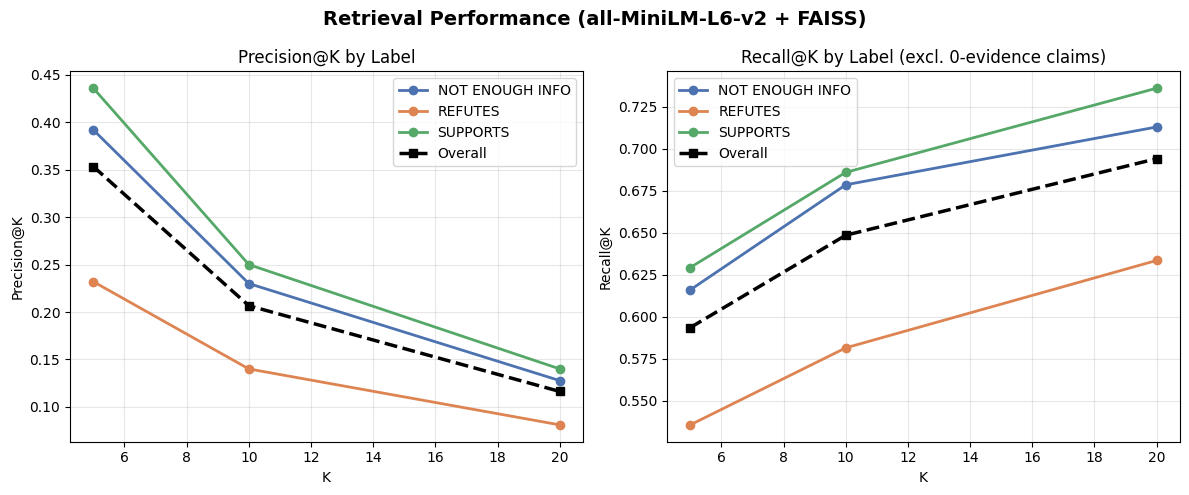

Saved: /content/drive/MyDrive/feverous-validation/figures/fig5_2_retrieval.png


In [13]:
# Cell 12: Plot retrieval metrics (Figure 5.2)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Retrieval Performance (all-MiniLM-L6-v2 + FAISS)', fontsize=14, fontweight='bold')

labels_list = sorted(df['label'].unique())
colors = ['#4c72b0', '#dd8452', '#55a868']

# Precision@K
ax = axes[0]
for label, color in zip(labels_list, colors):
    sub = df[df['label'] == label]
    vals = [sub[f'P@{k}'].mean() for k in K_VALUES]
    ax.plot(K_VALUES, vals, marker='o', label=label, color=color, linewidth=2)
overall_p = [df[f'P@{k}'].mean() for k in K_VALUES]
ax.plot(K_VALUES, overall_p, marker='s', label='Overall', color='black', linewidth=2.5, linestyle='--')
ax.set_xlabel('K')
ax.set_ylabel('Precision@K')
ax.set_title('Precision@K by Label')
ax.legend()
ax.grid(True, alpha=0.3)

# Recall@K (NaN-safe)
ax = axes[1]
for label, color in zip(labels_list, colors):
    sub = df[df['label'] == label]
    vals = [sub[f'R@{k}'].dropna().mean() for k in K_VALUES]
    ax.plot(K_VALUES, vals, marker='o', label=label, color=color, linewidth=2)
overall_r = [df[f'R@{k}'].dropna().mean() for k in K_VALUES]
ax.plot(K_VALUES, overall_r, marker='s', label='Overall', color='black', linewidth=2.5, linestyle='--')
ax.set_xlabel('K')
ax.set_ylabel('Recall@K')
ax.set_title('Recall@K by Label (excl. 0-evidence claims)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
FIG_DIR = os.path.join(BASE_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
fig_path = os.path.join(FIG_DIR, 'fig5_2_retrieval.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {fig_path}')

In [14]:
# Cell 13: Save FAISS index and embeddings for reuse in Day 4
faiss.write_index(index, os.path.join(DATA_DIR, 'faiss_index.bin'))
np.save(os.path.join(DATA_DIR, 'corpus_embeddings.npy'), corpus_embeddings)
np.save(os.path.join(DATA_DIR, 'claim_embeddings.npy'), claim_embeddings)

print('FAISS index and embeddings saved for Day 4 reuse')
print(f'  faiss_index.bin       — {index.ntotal} vectors')
print(f'  corpus_embeddings.npy — shape {corpus_embeddings.shape}')
print(f'  claim_embeddings.npy  — shape {claim_embeddings.shape}')

FAISS index and embeddings saved for Day 4 reuse
  faiss_index.bin       — 4571 vectors
  corpus_embeddings.npy — shape (4571, 384)
  claim_embeddings.npy  — shape (450, 384)


## Day 2 Complete

**First real metrics in hand!**

Files saved:
- `outputs/retrieval_results.csv` - P@K and R@K per claim
- `figures/fig5_2_retrieval.png` - Figure 5.2 (draft)
- `data/faiss_index.bin` - FAISS index (reused in Day 4)
- `data/corpus_embeddings.npy` - pre-computed embeddings
- `data/claim_embeddings.npy` - pre-computed claim embeddings

Next: Open `Day3_Baselines.ipynb`